In [15]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/input/datasets/vuquoctuan11/studentperformances/StudentPerformanceFactors.csv")
numeric_cols = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity",
    "Exam_Score"
]


ten_tieng_viet = {
    "Hours_Studied": "Giờ học",
    "Attendance": "Chuyên cần",
    "Sleep_Hours": "Giờ ngủ",
    "Previous_Scores": "Điểm trước đây",
    "Tutoring_Sessions": "Buổi học thêm",
    "Physical_Activity": "Hoạt động thể chất",
    "Exam_Score": "Điểm thi"
}

corr = (
    df[numeric_cols]
    .rename(columns=ten_tieng_viet)
    .corr()
)

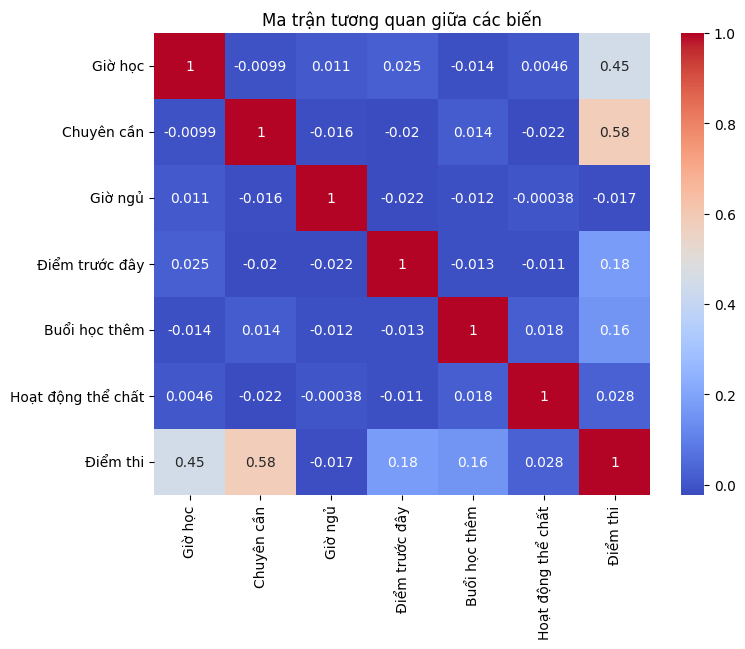

In [16]:
#1
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Ma trận tương quan giữa các biến")
plt.show()

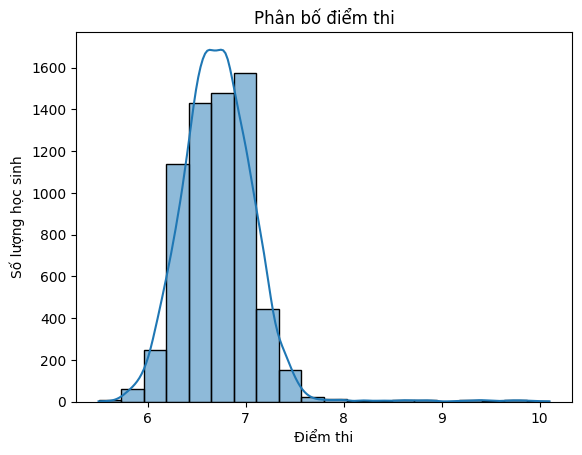

In [17]:
#2
sns.histplot(
    df["Exam_Score"],
    bins=20,
    kde=True
)

plt.title("Phân bố điểm thi")
plt.xlabel("Điểm thi")
plt.ylabel("Số lượng học sinh")

plt.show()

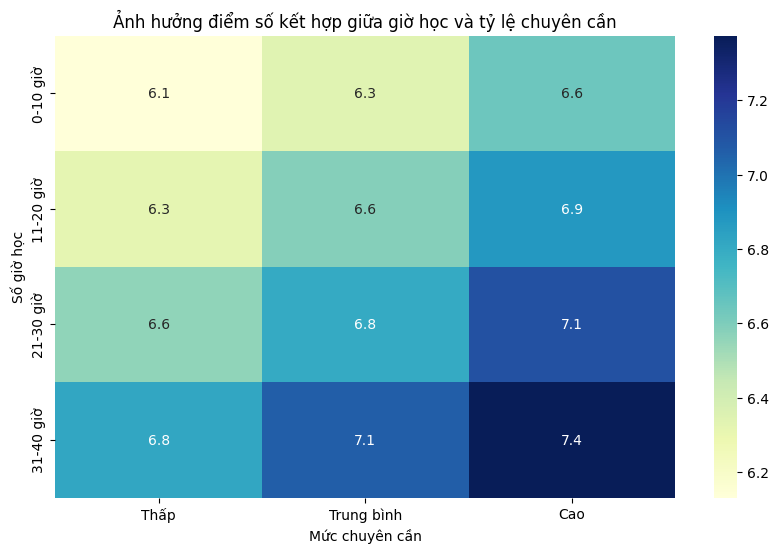

In [18]:
#3
df["Nhóm_Chuyên_Cần"] = pd.cut(
    df["Attendance"],
    bins=[0, 70, 85, 100],
    labels=["Thấp", "Trung bình", "Cao"]
)

df["Nhóm_Giờ_Học"] = pd.cut(
    df["Hours_Studied"],
    bins=[0, 10, 20, 30, 40],
    labels=[
        "0-10 giờ",
        "11-20 giờ",
        "21-30 giờ",
        "31-40 giờ"
    ]
)
pivot = df.pivot_table(
    values="Exam_Score",
    index="Nhóm_Giờ_Học",
    columns="Nhóm_Chuyên_Cần",
    aggfunc="mean",
    observed=False
)

plt.figure(figsize=(10,6))

sns.heatmap(
    pivot,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f"
)

plt.title("Ảnh hưởng điểm số kết hợp giữa giờ học và tỷ lệ chuyên cần")

plt.xlabel("Mức chuyên cần")
plt.ylabel("Số giờ học")

plt.show()

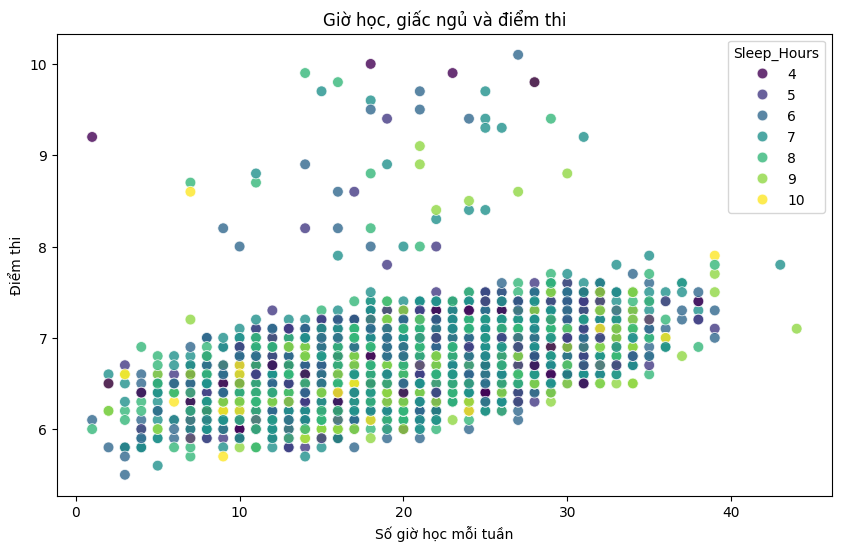

In [19]:
#4
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score",
    hue="Sleep_Hours",
    palette="viridis",
    s=60,
    alpha=0.8
)

plt.title("Giờ học, giấc ngủ và điểm thi")

plt.xlabel("Số giờ học mỗi tuần")
plt.ylabel("Điểm thi")

plt.show()

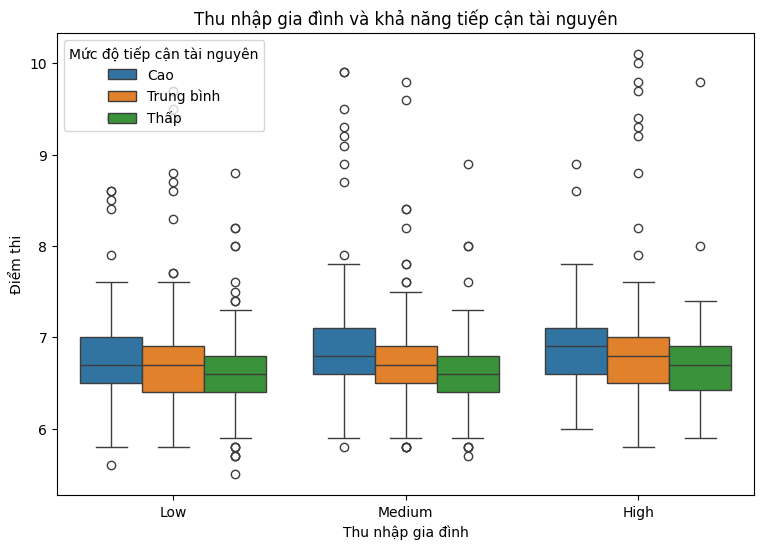

In [27]:
#5
plt.figure(figsize=(9,6))

ax = sns.boxplot(
    data=df,
    x="Family_Income",
    y="Exam_Score",
    hue="Access_to_Resources"
)

legend = ax.legend(
    title="Mức độ tiếp cận tài nguyên"
)

new_labels = ["Cao", "Trung bình", "Thấp"]

for text, label in zip(legend.get_texts(), new_labels):
    text.set_text(label)

plt.title("Thu nhập gia đình và khả năng tiếp cận tài nguyên")
plt.xlabel("Thu nhập gia đình")
plt.ylabel("Điểm thi")

plt.show()

In [ ]:
#6
sns.boxplot(
    data=df,
    x="Parental_Involvement",
    y="Exam_Score"
)

plt.title("Mức độ quan tâm của phụ huynh")

plt.xlabel("Mức độ quan tâm")
plt.ylabel("Điểm thi")

plt.show()

In [ ]:
#7
plot_df = df.copy()

plot_df["Motivation_Level"] = plot_df["Motivation_Level"].replace({
    "Low": "Thấp",
    "Medium": "Trung bình",
    "High": "Cao"
})

plot_df["Teacher_Quality"] = plot_df["Teacher_Quality"].replace({
    "Low": "Thấp",
    "Medium": "Trung bình",
    "High": "Cao"
})

plt.figure(figsize=(9,6))

sns.pointplot(
    data=plot_df,
    x="Motivation_Level",
    y="Exam_Score",
    hue="Teacher_Quality",
    order=["Thấp", "Trung bình", "Cao"],
    hue_order=["Thấp", "Trung bình", "Cao"],
    markers=["o", "s", "D"],
    linestyles="-",
    errorbar=None
)

plt.title("Ảnh hưởng của động lực học tập và chất lượng giáo viên", fontsize=15)

plt.xlabel("Mức độ động lực học tập", fontsize=12)
plt.ylabel("Điểm thi trung bình", fontsize=12)

plt.legend(
    title="Chất lượng giáo viên",
    labels=["Thấp", "Trung bình", "Cao"]
)

plt.grid(axis="y", alpha=0.3)

plt.show()

In [3]:
#8
df["Nhóm_Giờ_Học"] = pd.cut(
    df["Hours_Studied"],
    bins=[0,10,20,30,40],
    labels=[
        "0-10 giờ",
        "11-20 giờ",
        "21-30 giờ",
        "31-40 giờ"
    ]
)


df["Nhóm_Chuyên_Cần"] = pd.cut(
    df["Attendance"],
    bins=[0,70,85,100],
    labels=[
        "Thấp",
        "Trung bình",
        "Cao"
    ]
)


pivot = df.pivot_table(
    values="Exam_Score",
    index="Nhóm_Giờ_Học",
    columns="Nhóm_Chuyên_Cần",
    aggfunc="mean",
    observed=False
)


plt.figure(figsize=(8,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label":"Điểm thi trung bình"}
)

plt.title(
    "Ảnh hưởng kết hợp giữa giờ học và tỷ lệ chuyên cần",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mức độ chuyên cần")
plt.ylabel("Số giờ học mỗi tuần")

plt.tight_layout()

plt.show()

NameError: name 'pd' is not defined